In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.shape

(7043, 21)

In [ ]:
pd.set_option('display.max_columns', None)  # Show all columns in the DataFrame
pd.set_option('display.max_rows', None)     # Show all rows in the DataFrame

In [4]:
df.sample(2)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
4460,0365-GXEZS,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,Yes,Yes,No,No,Month-to-month,No,Electronic check,78.2,1468.75,No
1408,5678-VFNEQ,Female,0,Yes,No,71,Yes,Yes,Fiber optic,Yes,No,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),104.1,7412.25,No


In [5]:
df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [6]:
binary_cols = [
    'gender', 'SeniorCitizen' ,'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn'
]

# Map Yes/No and Male/Female to 0/1
df[binary_cols] = df[binary_cols].replace({
    'Yes': 1, 'No': 0,
    'Male': 1, 'Female': 0
})

In [7]:
df.sample(3)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
2923,4402-FTBXC,1,0,0,0,54,1,No,Fiber optic,Yes,No,Yes,No,Yes,No,Month-to-month,0,Mailed check,89.80,4667,0
531,1403-GYAFU,1,0,1,1,70,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,0,Credit card (automatic),20.05,1360.25,0
6622,4662-EKDPQ,1,0,0,0,2,1,Yes,DSL,No,No,No,No,No,Yes,Month-to-month,0,Bank transfer (automatic),62.05,118.3,1


In [8]:
#one hot encoding 

In [9]:
multi_cat_cols = [
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaymentMethod'
]

df = pd.get_dummies(df, columns=multi_cat_cols, drop_first=True)

In [10]:
df.sample(3)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
2155,0524-IAVZO,0,0,1,0,30,1,1,85.00,2624.25,1,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,True,False
2728,6402-SSEJG,0,0,0,0,25,0,0,61.05,1540.2,0,True,False,False,False,False,True,False,True,False,True,False,False,False,True,False,True,True,False,False,True,False
3910,8938-UMKPI,0,0,0,0,47,1,1,106.40,5127.95,1,False,True,True,False,False,False,False,True,False,True,False,False,False,True,False,True,False,False,False,True,False


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 32 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   customerID                             7043 non-null   object 
 1   gender                                 7043 non-null   int64  
 2   SeniorCitizen                          7043 non-null   int64  
 3   Partner                                7043 non-null   int64  
 4   Dependents                             7043 non-null   int64  
 5   tenure                                 7043 non-null   int64  
 6   PhoneService                           7043 non-null   int64  
 7   PaperlessBilling                       7043 non-null   int64  
 8   MonthlyCharges                         7043 non-null   float64
 9   TotalCharges                           7043 non-null   object 
 10  Churn                                  7043 non-null   int64  
 11  Mult

In [12]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [13]:
df=df.drop('customerID',axis=1)

In [14]:
bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int)

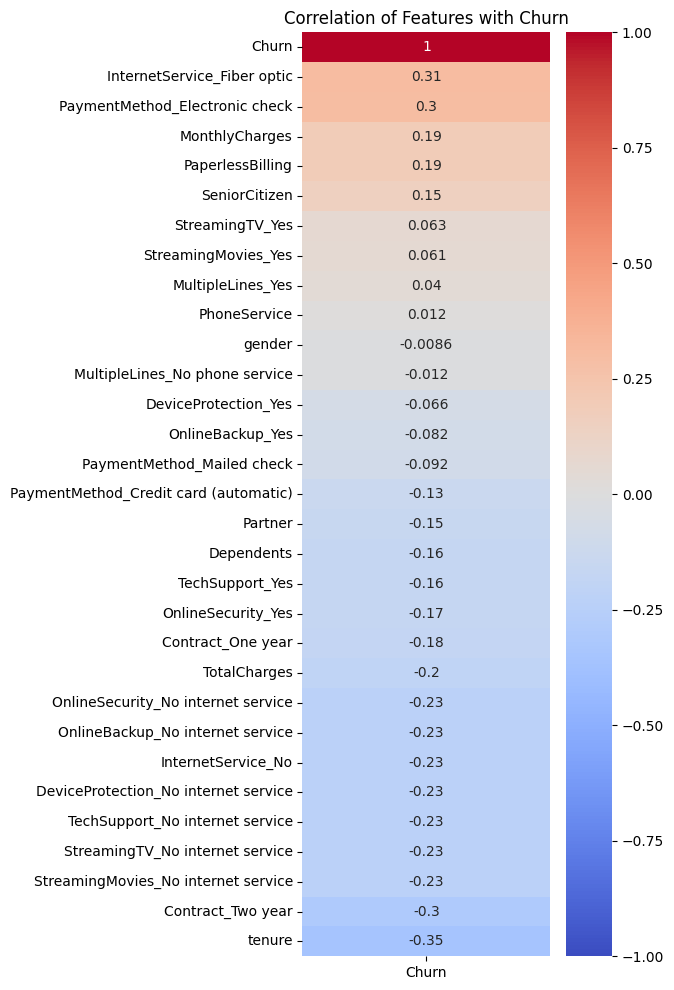

In [15]:
corr_matrix = df.corr(numeric_only=True)

# Focus on correlation with Churn
churn_corr = corr_matrix[['Churn']].sort_values(by='Churn', ascending=False)

# Plot heatmap
plt.figure(figsize=(4, 12))
sns.heatmap(churn_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation of Features with Churn')
plt.show()

## Dataset Preparation Checklist Before Calculating VIF

| Consideration | What you should do | Why? |
|---|---|---|
| **Missing values** | Handle all NaN values. | VIF cannot handle missing values. |
| **Data types** | Convert features into numeric format. | VIF requires numerical inputs. |
| **Target variable** | Exclude `Churn`. | VIF is calculated only on independent variables. |
| **Categorical variables** | Apply One-Hot Encoding. | Categorical text cannot be used directly. |
| **Dummy variable trap** | Drop one category from each categorical feature. | Avoids perfect multicollinearity. |
| **Feature engineering** | Check for redundant features. | Derived features may duplicate existing information. |

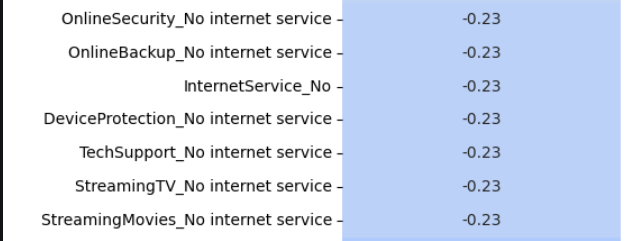

In [16]:
df['No_internet_service'] = (
    df['OnlineSecurity_No internet service'] |
    df['OnlineBackup_No internet service'] |
    df['DeviceProtection_No internet service'] |
    df['TechSupport_No internet service'] |
    df['StreamingTV_No internet service'] |
    df['StreamingMovies_No internet service']
).astype(int)

In [17]:
drop_cols = [col for col in df.columns if 'No internet service' in col]
df = df.drop(columns=drop_cols)

In [18]:
df['No_phone_service'] = df['MultipleLines_No phone service'].astype(int)
df = df.drop(columns=['MultipleLines_No phone service'])

In [19]:
X = df.drop(columns=['Churn'])
bool_cols = X.select_dtypes(include='bool').columns
X[bool_cols] = X[bool_cols].astype(int)

In [20]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import numpy as np

In [21]:
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

In [22]:
vif_data = pd.DataFrame()
vif_data['feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif_data = vif_data.sort_values(by='VIF', ascending=False)
vif_data

d:\My Projects\Churn\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,feature,VIF
23,No_internet_service,inf
11,InternetService_No,inf
5,PhoneService,1773.528816
7,MonthlyCharges,866.089640
10,InternetService_Fiber optic,148.500814
24,No_phone_service,60.842267
17,StreamingMovies_Yes,24.156394
16,StreamingTV_Yes,24.080019
8,TotalCharges,10.811490
4,tenure,7.584453


MOdel

In [23]:
df['Churn'].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

**False Negative (FN): You predict a customer will not churn, but they actually leave → you miss the chance to intervene and keep them.**

**False Positive (FP): You predict a customer will churn, but they stay → you might spend some retention resources unnecessarily.**

**1- If retention campaigns are cheap → prioritize recall (catch every possible churner).**

**2- If retention campaigns are expensive → balance precision and recall using F1 score**

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
X = df.drop(columns=['Churn'])
y = df['Churn']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

THRESHOLD = 0.3  # lower than 0.5 to boost recal

In [25]:
from xgboost import XGBClassifier
import time
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss'
)

# Training timer
start_train = time.time()
xgb.fit(X_train, y_train)
train_time = time.time() - start_train
print(f"⏱ Training time: {train_time:.2f} seconds")

# Prediction timer
start_pred = time.time()
proba = xgb.predict_proba(X_test)[:, 1]
y_pred = (proba >= THRESHOLD).astype(int)
pred_time = time.time() - start_pred
print(f"⏱ Prediction time: {pred_time:.4f} seconds")

# Classification report
print(classification_report(y_test, y_pred, digits=3))

⏱ Training time: 1.98 seconds
⏱ Prediction time: 0.0090 seconds
              precision    recall  f1-score   support

           0      0.914     0.687     0.784      1035
           1      0.487     0.821     0.611       374

    accuracy                          0.722      1409
   macro avg      0.700     0.754     0.698      1409
weighted avg      0.800     0.722     0.738      1409



In [26]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

proba = xgb.predict_proba(X_test)[:, 1]

print("Threshold tuning for XGBoost")

print(f"{'Thresh':<8}{'Prec_1':<8}{'Rec_1':<8}{'F1_1':<8}")
for thresh in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    preds = (proba >= thresh).astype(int)
    prec = precision_score(y_test, preds, pos_label=1)
    rec = recall_score(y_test, preds, pos_label=1)
    f1 = f1_score(y_test, preds, pos_label=1)
    print(f"{thresh:<8}{prec:<8.3f}{rec:<8.3f}{f1:<8.3f}")

Threshold tuning for XGBoost
Thresh  Prec_1  Rec_1   F1_1    
0.25    0.465   0.842   0.599   
0.3     0.487   0.821   0.611   
0.35    0.508   0.799   0.621   
0.4     0.520   0.767   0.620   
0.45    0.528   0.722   0.610   
0.5     0.541   0.684   0.604   


## Hyperparametertuning

In [27]:
import optuna
from xgboost import XGBClassifier
from sklearn.metrics import recall_score
from sklearn.model_selection import train_test_split

# Objective function for Optuna
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 300, 800),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 5),
        "reg_lambda": trial.suggest_float("reg_lambda", 0, 5),
        "random_state": 42,
        "n_jobs": -1,
        "scale_pos_weight": (y_train == 0).sum() / (y_train == 1).sum(),
        "eval_metric": "logloss"
    }
    
    model = XGBClassifier(**params)
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    y_pred = (proba >= THRESHOLD).astype(int)  # Keep your tuned threshold
    return recall_score(y_test, y_pred, pos_label=1)  # Optimize recall for churners

# Run Optuna
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30)


d:\My Projects\Churn\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-11-09 19:14:57,971] A new study created in memory with name: no-name-2ea90f13-a3b0-4dc3-934a-44fb2e0ba3d1
[I 2026-11-09 19:14:58,205] Trial 0 finished with value: 0.9171122994652406 and parameters: {'n_estimators': 403, 'learning_rate': 0.16804841385338876, 'max_depth': 8, 'subsample': 0.9608206266298263, 'colsample_bytree': 0.9366721971338099, 'min_child_weight': 9, 'gamma': 3.4162243718206513, 'reg_alpha': 2.688580512199568, 'reg_lambda': 2.6656562832036803}. Best is trial 0 with value: 0.9171122994652406.
[I 2026-11-09 19:14:58,502] Trial 1 finished with value: 0.8850267379679144 and parameters: {'n_estimators': 368, 'learning_rate': 0.10105132388199484, 'max_depth': 9, 'subsample': 0.6177164036907151, 'colsample_bytree': 0.52216

In [28]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()


In [29]:
# Add the scale_pos_weight and fixed params to the best ones from Optuna
best_params = study.best_params
best_params.update({
    "random_state": 42,
    "n_jobs": -1,
    "scale_pos_weight": scale_pos_weight,
    "eval_metric": "logloss"
})

# Create model from best params
xgb = XGBClassifier(**best_params)

# Training timer
start_train = time.time()
xgb.fit(X_train, y_train)
train_time = time.time() - start_train
print(f"⏱ Training time: {train_time:.2f} seconds")

# Prediction timer
start_pred = time.time()
proba = xgb.predict_proba(X_test)[:, 1]
y_pred = (proba >= THRESHOLD).astype(int)
pred_time = time.time() - start_pred
print(f"⏱ Prediction time: {pred_time:.4f} seconds")

# Classification report
print(classification_report(y_test, y_pred, digits=3))

⏱ Training time: 0.41 seconds
⏱ Prediction time: 0.0070 seconds
              precision    recall  f1-score   support

           0      0.953     0.571     0.714      1035
           1      0.437     0.922     0.593       374

    accuracy                          0.664      1409
   macro avg      0.695     0.747     0.654      1409
weighted avg      0.816     0.664     0.682      1409



MLFLows

In [31]:
import mlflow
import mlflow.sklearn  # or mlflow.xgboost
from pathlib import Path

# Force MLflow to always use the project root's mlruns folder
cwd = Path.cwd().resolve()
project_root = cwd.parent if cwd.name.lower() == "notebooks" else cwd
mlruns_path = project_root / "mlruns"
mlruns_path.mkdir(parents=True, exist_ok=True)

# Set valid Windows-compatible tracking URI
mlflow.set_tracking_uri(mlruns_path.as_uri())
mlflow.set_experiment("Telco Churn - XGBoost")
print("Tracking URI:", mlflow.get_tracking_uri())
with mlflow.start_run():
    # Calculate scale_pos_weight
    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

    # Best params from Optuna
    best_params = study.best_params
    best_params.update({
        "random_state": 42,
        "n_jobs": -1,
        "scale_pos_weight": scale_pos_weight,
        "eval_metric": "logloss"
    })

    # Log parameters
    mlflow.log_params(best_params)

    # Training timer
    start_train = time.time()
    xgb = XGBClassifier(**best_params)
    xgb.fit(X_train, y_train)
    train_time = time.time() - start_train
    mlflow.log_metric("train_time", train_time)

    # Prediction
    start_pred = time.time()
    proba = xgb.predict_proba(X_test)[:, 1]
    y_pred = (proba >= THRESHOLD).astype(int)
    pred_time = time.time() - start_pred
    mlflow.log_metric("pred_time", pred_time)

    # Metrics
    precision = precision_score(y_test, y_pred, pos_label=1)
    recall = recall_score(y_test, y_pred, pos_label=1)
    f1 = f1_score(y_test, y_pred, pos_label=1)
    auc = roc_auc_score(y_test, proba)

    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1", f1)
    mlflow.log_metric("roc_auc", auc)

    # Save model
    mlflow.xgboost.log_model(xgb, "model")

    print(classification_report(y_test, y_pred, digits=3))

2026/11/09 19:22:15 INFO mlflow.tracking.fluent: Experiment with name 'Telco Churn - XGBoost' does not exist. Creating a new experiment.


Tracking URI: file:///D:/My%20Projects/Churn/mlruns


d:\My Projects\Churn\.venv\Lib\site-packages\xgboost\sklearn.py:1028: UserWarning: [19:22:17] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\c_api\c_api.cc:1427: Saving model in the UBJSON format as default.  You can use file extension: `json`, `ubj` or `deprecated` to choose between formats.
  self.get_booster().save_model(fname)


              precision    recall  f1-score   support

           0      0.953     0.571     0.714      1035
           1      0.437     0.922     0.593       374

    accuracy                          0.664      1409
   macro avg      0.695     0.747     0.654      1409
weighted avg      0.816     0.664     0.682      1409

